# 06 — First learning problem: linear regression

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–05: tensors and broadcasting, affine maps and `nn.Linear`, gradients and gradient descent, likelihood and MLE, autograd |
| **You will learn** | How to fit a model by minimizing a loss; how mean squared error follows from Gaussian noise; how to write the same training loop with manual gradients, with autograd, and with `nn.Module` + `torch.optim`; vectorized gradients for many features; why feature scaling makes gradient descent fast |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU, under a minute. One optional GPU cell. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import time

from torch import nn

from dlcourse.plotting import COLORS

## The motivating problem

Someone measured a quantity $y$ at 100 values of $x$. The measurements came from an unknown straight line, but each one carries random noise. **Can we recover the line from the noisy points?**

This is the smallest real learning problem: a model with parameters, data, a loss that says how wrong the model is, and an algorithm that reduces the loss. We will solve it three times, each time closer to how real deep learning code is written:

1. **manual gradients** — we derive the derivatives on paper and code them;
2. **autograd** — PyTorch computes the derivatives (notebook 05);
3. **`nn.Module` + `torch.optim`** — the standard PyTorch training loop used for every model in this course.

All three must agree with each other, and with an exact answer computed by linear algebra.

## 1. The data, the model, and the loss

We generate the data ourselves, so we know the truth and can check our answers:

$$y_i = 2.5\,x_i - 1 + \varepsilon_i, \qquad x_i \sim \text{Uniform}[-2, 2], \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2),\ \sigma = 0.5,$$

for $i = 1, \dots, N$ with $N = 100$. In this section $x$ and $y$ are 1-D tensors of shape `(N,)`: one number per example.

In [3]:
N = 100
TRUE_W, TRUE_B, SIGMA = 2.5, -1.0, 0.5

gen = torch.Generator().manual_seed(0)
x = 4 * torch.rand(N, generator=gen) - 2                     # (N,), uniform on [-2, 2]
y = TRUE_W * x + TRUE_B + SIGMA * torch.randn(N, generator=gen)  # (N,)
print("x:", x.shape, x.dtype, "  y:", y.shape, y.dtype)
print("first three points:", [(round(a, 3), round(b, 3)) for a, b in zip(x[:3].tolist(), y[:3].tolist())])

x: torch.Size([100]) torch.float32   y: torch.Size([100]) torch.float32
first three points: [(-0.015, -2.344), (1.073, 0.834), (-1.646, -5.229)]


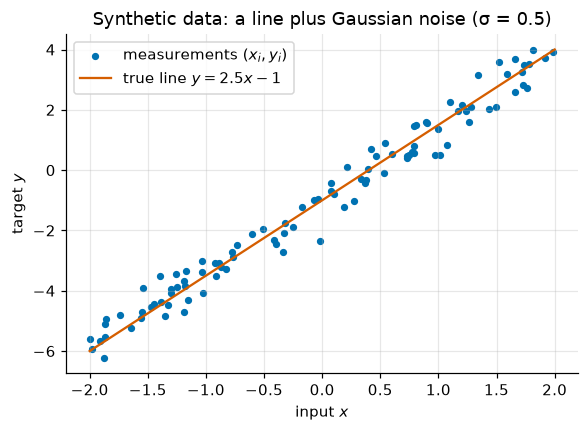

In [4]:
grid_x = torch.linspace(-2, 2, 2)
plt.scatter(x, y, s=14, label="measurements $(x_i, y_i)$")
plt.plot(grid_x, TRUE_W * grid_x + TRUE_B, color=COLORS[1], label="true line $y = 2.5x - 1$")
plt.xlabel("input $x$")
plt.ylabel("target $y$")
plt.title("Synthetic data: a line plus Gaussian noise (σ = 0.5)")
plt.legend()
plt.show()

The points scatter around the true line by about ±0.5 (one σ) vertically. In a real problem we would see only the dots, not the orange line.

### The model

Our **model** is a line with two **parameters**, a slope $w$ and an intercept (bias) $b$:

$$\hat{y}_i = w\,x_i + b.$$

$\hat{y}_i$ ("y-hat") is the model's **prediction** for example $i$. With $x$ of shape `(N,)` and scalars $w, b$, broadcasting (notebook 01) gives predictions of shape `(N,)`.

### The loss

The **loss** $L$ is one number that measures how wrong the predictions are. We use the **mean squared error**:

$$L(w, b) = \frac{1}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i)^2.$$

The difference $r_i = \hat{y}_i - y_i$ is the **residual** of example $i$.

Why squares, and not absolute values or fourth powers? Notebook 04 answered this. If the noise is Gaussian, $y_i \sim \mathcal{N}(w x_i + b, \sigma^2)$, then the negative log-likelihood of the data is

$$-\log p(y \mid x; w, b) = \sum_{i=1}^{N}\left[\frac{(y_i - w x_i - b)^2}{2\sigma^2} + \tfrac12 \log(2\pi\sigma^2)\right] = \frac{N}{2\sigma^2}\,L(w, b) + \text{const}.$$

For fixed $\sigma$, the constant and the positive factor $N/(2\sigma^2)$ do not change *where* the minimum is. So **minimizing MSE is maximum-likelihood estimation under Gaussian noise**. A different noise assumption gives a different loss; Exercise 4 tries one.

Let's check that identity numerically with `torch.distributions.Normal`, at an arbitrary $(w, b)$:

In [5]:
def predict(w, b, x):
    """Line model. x: (N,), w and b: scalars -> (N,)."""
    return w * x + b


def mse(y_hat, y):
    """Mean squared error between two tensors of the same shape."""
    return ((y_hat - y) ** 2).mean()


w_try, b_try = 1.0, 0.5
y_hat = predict(w_try, b_try, x)                                     # (N,)
nll = -torch.distributions.Normal(y_hat, SIGMA).log_prob(y).sum()
const = N / 2 * torch.log(torch.tensor(2 * torch.pi * SIGMA**2))
print(f"Gaussian NLL                 = {nll.item():.4f}")
print(f"N/(2σ²) · MSE + N/2·log(2πσ²) = {(N / (2 * SIGMA**2) * mse(y_hat, y) + const).item():.4f}")

Gaussian NLL                 = 1105.3193
N/(2σ²) · MSE + N/2·log(2πσ²) = 1105.3193


### Checkpoint 1.1

By hand first, then in code: three points $x = (0, 1, 2)$, $y = (1, 2, 2)$, and the line $w = 1$, $b = 0.5$. Compute the predictions `y_hat_small` (shape `(3,)`) and the MSE `mse_small` (a 0-d tensor or a float). Do it on paper before running the check.

<details>
<summary><b>💡 Hint</b></summary>

The predictions are $0.5, 1.5, 2.5$, so the residuals are $-0.5, -0.5, +0.5$. Square, then average.

</details>

In [6]:
x_small = torch.tensor([0.0, 1.0, 2.0])
y_small = torch.tensor([1.0, 2.0, 2.0])
y_hat_small = 1.0 * x_small + 0.5
mse_small = ((y_hat_small - y_small) ** 2).mean()

In [7]:
check_shape(y_hat_small, (3,), "y_hat_small")
check_close(y_hat_small, torch.tensor([0.5, 1.5, 2.5]), "y_hat_small")
check_close(mse_small, 0.25, "mse_small")
passed("Checkpoint 1.1")

✅ Checkpoint 1.1 passed


## 2. The loss landscape and the exact answer

$L(w, b)$ is a function of two numbers, so we can draw it. We evaluate it on a $200 \times 200$ grid of $(w, b)$ values in one broadcasted expression: the grid of slopes has shape `(200, 1, 1)`, the grid of intercepts `(1, 200, 1)`, and $x$ is viewed as `(1, 1, N)`. The residuals then have shape `(200, 200, N)`, and averaging over the last axis gives a `(200, 200)` table of losses.

In [8]:
ws = torch.linspace(-1.0, 5.0, 200)   # (200,) slopes
bs = torch.linspace(-4.0, 3.0, 200)   # (200,) intercepts
residuals = ws[:, None, None] * x[None, None, :] + bs[None, :, None] - y[None, None, :]  # (200, 200, N)
L_grid = (residuals**2).mean(dim=-1)  # (200, 200): L_grid[i, j] = L(ws[i], bs[j])
print("L_grid:", L_grid.shape)
i, j = divmod(L_grid.argmin().item(), L_grid.shape[1])
print(f"lowest grid point: w = {ws[i].item():.3f}, b = {bs[j].item():.3f}, L = {L_grid[i, j].item():.4f}")

L_grid: torch.Size([200, 200])
lowest grid point: w = 2.407, b = -1.010, L = 0.1979


### Least squares: the exact minimizer

For this model we do not actually need an iterative algorithm. Stack the inputs into a **design matrix** $A \in \mathbb{R}^{N \times 2}$ whose row $i$ is $(x_i, 1)$, and the parameters into $\boldsymbol{\theta} = (w, b)$. Then the predictions are $\hat{\mathbf{y}} = A\boldsymbol{\theta}$, and minimizing $L = \frac1N\|A\boldsymbol{\theta} - \mathbf{y}\|^2$ is a **linear least-squares** problem. `torch.linalg.lstsq` solves it directly (we derive *why* a direct solution exists in Section 6; for now it is our ground truth).

The column of ones is how the intercept enters: $(x_i, 1)\cdot(w, b) = w x_i + b$. We solve in `float64` on the CPU for an accurate reference.

In [9]:
A = torch.stack([x.double(), torch.ones(N, dtype=torch.float64)], dim=1)   # (N, 2)
theta_ls = torch.linalg.lstsq(A, y.double().unsqueeze(1)).solution.squeeze(1)  # (2,)
w_ls, b_ls = theta_ls.tolist()
print(f"least squares: w = {w_ls:.6f}, b = {b_ls:.6f}")
print(f"true line:     w = {TRUE_W:.6f}, b = {TRUE_B:.6f}")

least squares: w = 2.414268, b = -1.005371
true line:     w = 2.500000, b = -1.000000


The least-squares answer is close to the truth but not equal to it: with only 100 noisy points, the noise itself pulls the best-fitting line a little. Every method below must reproduce `w_ls, b_ls` — not `2.5, -1` — because they all minimize the same loss on the same data.

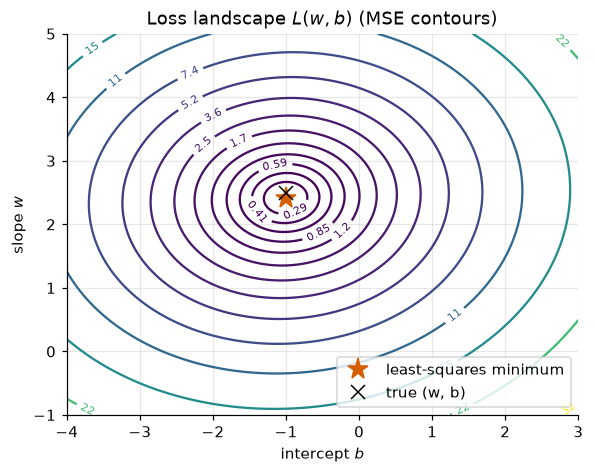

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
levels = torch.logspace(-0.7, 1.5, 15)
cs = ax.contour(bs, ws, L_grid, levels=levels, cmap="viridis")
ax.clabel(cs, fmt="%.2g", fontsize=7)
ax.plot(b_ls, w_ls, "*", color=COLORS[1], markersize=14, label="least-squares minimum")
ax.plot(TRUE_B, TRUE_W, "x", color="k", markersize=9, label="true (w, b)")
ax.set_xlabel("intercept $b$")
ax.set_ylabel("slope $w$")
ax.set_title("Loss landscape $L(w, b)$ (MSE contours)")
ax.legend(loc="lower right")
plt.show()

The contours are closed, nearly circular ellipses around a single minimum: the MSE of a linear model is a quadratic bowl with no other valleys. The star and the cross are close but not identical — the gap is the effect of noise on 100 points.

### Checkpoint 2.1

Compute the training loss at the least-squares parameters (`loss_at_ls`) and at the true parameters $w=2.5, b=-1$ (`loss_at_true`), using `predict` and `mse` on the `float32` data `x`, `y`. Which is smaller? Think about it before running the check.

<details>
<summary><b>💡 Hint</b></summary>

`mse(predict(w, b, x), y)` with the two parameter pairs. By definition, nothing beats the minimizer on the data it was fitted to.

</details>

In [11]:
loss_at_ls = mse(predict(w_ls, b_ls, x), y)
loss_at_true = mse(predict(TRUE_W, TRUE_B, x), y)
print(f"loss at least squares: {float(loss_at_ls):.4f}   loss at true line: {float(loss_at_true):.4f}")

loss at least squares: 0.1978   loss at true line: 0.2079


In [12]:
check_close(loss_at_ls, mse(predict(w_ls, b_ls, x), y), "loss_at_ls")
check_close(loss_at_true, mse(predict(TRUE_W, TRUE_B, x), y), "loss_at_true")
check(float(loss_at_ls) <= float(loss_at_true), "the least-squares line minimizes the training loss, so its loss cannot be larger")
passed("Checkpoint 2.1")

✅ Checkpoint 2.1 passed


The fitted line has *lower* training loss than the true line. A model fitted to data adapts to that data's particular noise. Whether it then does well on *new* data is the question of generalization, the subject of notebook 22.

## 3. Gradient descent with manual gradients

The closed form works only for this special model. For neural networks there is no formula, and we use gradient descent instead (notebook 03): repeatedly step against the gradient,

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}, \qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b},$$

with learning rate $\eta > 0$. We need the two partial derivatives.

### Deriving the gradient

$L = \frac1N \sum_i r_i^2$ with $r_i = w x_i + b - y_i$. By the chain rule, $\frac{\partial}{\partial w} r_i^2 = 2 r_i \frac{\partial r_i}{\partial w} = 2 r_i x_i$, and $\frac{\partial}{\partial b} r_i^2 = 2 r_i \cdot 1$. Averaging over examples:

$$\frac{\partial L}{\partial w} = \frac{2}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i)\,x_i, \qquad \frac{\partial L}{\partial b} = \frac{2}{N}\sum_{i=1}^{N} (\hat{y}_i - y_i).$$

In words: each example pushes the slope in proportion to its residual times its input, and pushes the intercept in proportion to its residual alone.

In [13]:
def mse_grads(w, b, x, y):
    """Gradient of the MSE of the line w*x + b. x, y: (N,). Returns (dL/dw, dL/db) as 0-d tensors."""
    r = w * x + b - y                  # (N,) residuals
    return 2 * (r * x).mean(), 2 * r.mean()

A derivation can be wrong, so we test it. Notebook 03's **central finite difference** approximates a derivative by $\frac{L(w+h) - L(w-h)}{2h}$, with error proportional to $h^2$. We compare in `float64`, where rounding is small enough for $h = 10^{-5}$ to give many correct digits.

In [14]:
x64, y64 = x.double(), y.double()
w0_, b0_, h = 0.7, 0.3, 1e-5
gw, gb = mse_grads(w0_, b0_, x64, y64)
fd_w = (mse(predict(w0_ + h, b0_, x64), y64) - mse(predict(w0_ - h, b0_, x64), y64)) / (2 * h)
fd_b = (mse(predict(w0_, b0_ + h, x64), y64) - mse(predict(w0_, b0_ - h, x64), y64)) / (2 * h)
print(f"dL/dw: formula {gw.item():.10f}   finite difference {fd_w.item():.10f}")
print(f"dL/db: formula {gb.item():.10f}   finite difference {fd_b.item():.10f}")
check_close(gw, fd_w, "dL/dw", rtol=1e-7, atol=1e-8)
check_close(gb, fd_b, "dL/db", rtol=1e-7, atol=1e-8)
passed("Gradient formula matches finite differences")

dL/dw: formula -4.8391400999   finite difference -4.8391400999
dL/db: formula 2.7695579083   finite difference 2.7695579083
✅ Gradient formula matches finite differences passed


### Checkpoint 3.1

Take **one** gradient-descent step by hand, starting from $w = 0$, $b = 0$ with $\eta = 0.1$, on the data `x`, `y`. Store the new parameters in `w_1` and `b_1`. Use `mse_grads`.

<details>
<summary><b>💡 Hint</b></summary>

`gw, gb = mse_grads(0.0, 0.0, x, y)`, then `w_1 = 0.0 - eta * gw` and the same for `b`.

</details>

In [15]:
eta = 0.1
gw, gb = mse_grads(0.0, 0.0, x, y)
w_1 = 0.0 - eta * gw
b_1 = 0.0 - eta * gb
print(f"after one step: w = {float(w_1):.4f}, b = {float(b_1):.4f}")

after one step: w = 0.6738, b = -0.2234


In [16]:
_gw, _gb = mse_grads(0.0, 0.0, x, y)
check_close(w_1, -eta * _gw, "w_1")
check_close(b_1, -eta * _gb, "b_1")
passed("Checkpoint 3.1")

✅ Checkpoint 3.1 passed


### The training loop

Now repeat the step. We start from $(w, b) = (-1, 2)$, far from the answer, so the path is visible, and record the parameters and the loss at every step. Notebook 03 showed that gradient descent on a quadratic is stable only for $\eta < 2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of the Hessian; Section 7 shows how to compute the Hessian, and Exercise 1 computes this bound for our data. For now, take it on trust that $\eta = 0.1$ is safely below it.

In [17]:
W0, B0, ETA, STEPS = -1.0, 2.0, 0.1, 100

w, b = torch.tensor(W0), torch.tensor(B0)
manual_path = [(w.item(), b.item())]
manual_losses = [mse(predict(w, b, x), y).item()]
for step in range(STEPS):
    gw, gb = mse_grads(w, b, x, y)
    w = w - ETA * gw
    b = b - ETA * gb
    manual_path.append((w.item(), b.item()))
    manual_losses.append(mse(predict(w, b, x), y).item())
manual_path = torch.tensor(manual_path)  # (STEPS + 1, 2): columns are w, b

print(f"gradient descent: w = {w.item():.6f}, b = {b.item():.6f}")
print(f"least squares:    w = {w_ls:.6f}, b = {b_ls:.6f}")
check_close(w, w_ls, "w after gradient descent", rtol=0, atol=1e-5)
check_close(b, b_ls, "b after gradient descent", rtol=0, atol=1e-5)
passed("Manual gradient descent reaches the least-squares solution")

gradient descent: w = 2.414268, b = -1.005370
least squares:    w = 2.414268, b = -1.005371
✅ Manual gradient descent reaches the least-squares solution passed


The tolerance is $10^{-5}$ because the data and the loop are in `float32`, which keeps about 7 significant digits, while the reference is `float64`.

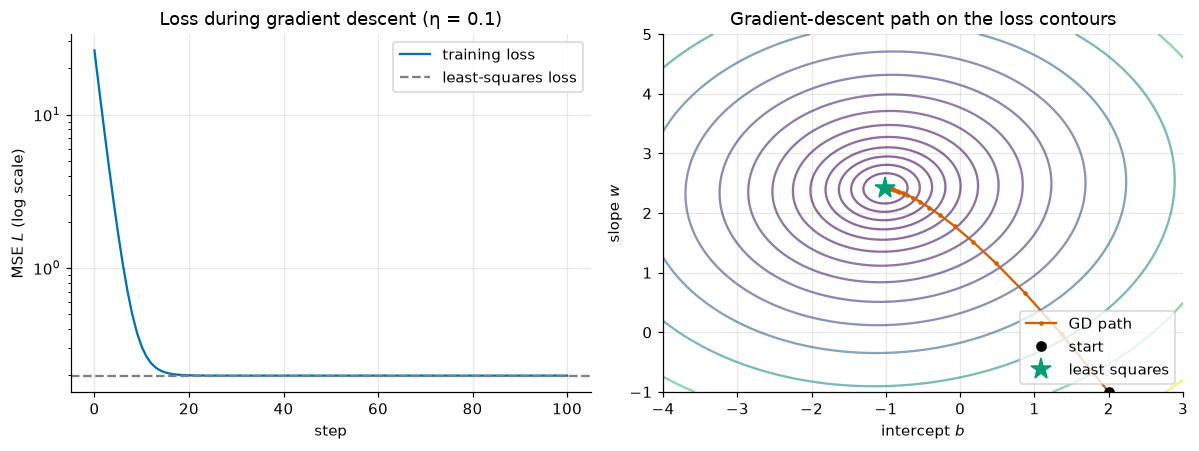

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.semilogy(manual_losses, color=COLORS[0], label="training loss")
ax1.axhline(mse(predict(w_ls, b_ls, x), y).item(), ls="--", color="gray", label="least-squares loss")
ax1.set_xlabel("step")
ax1.set_ylabel("MSE $L$ (log scale)")
ax1.set_title("Loss during gradient descent (η = 0.1)")
ax1.legend()

cs = ax2.contour(bs, ws, L_grid, levels=levels, cmap="viridis", alpha=0.6)
ax2.plot(manual_path[:, 1], manual_path[:, 0], ".-", color=COLORS[1], markersize=4, label="GD path")
ax2.plot(B0, W0, "o", color="k", label="start")
ax2.plot(b_ls, w_ls, "*", color=COLORS[2], markersize=14, label="least squares")
ax2.set_xlabel("intercept $b$")
ax2.set_ylabel("slope $w$")
ax2.set_title("Gradient-descent path on the loss contours")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

Left: the loss falls by two orders of magnitude in about 20 steps and then sits on the least-squares value. Right: each step moves at right angles to the contour it starts on (the gradient is perpendicular to the contours), and the path heads almost straight for the minimum. The bowl is nearly round, so there is no zig-zag. Section 7 shows what happens when it is not.

## 4. The same loop with autograd

Deriving gradients by hand does not scale to networks with millions of parameters. Autograd (notebook 05) computes them for us. The recipe:

1. make the parameters leaf tensors with `requires_grad=True`;
2. compute the loss with ordinary tensor operations; autograd records the graph;
3. call `loss.backward()`, which fills `w.grad` and `b.grad` with $\partial L/\partial w$ and $\partial L/\partial b$;
4. update the parameters inside `torch.no_grad()`, so the update itself is not recorded in the graph;
5. zero the gradients, because `backward()` **adds** into `.grad` (notebook 05).

Same start, same $\eta$, same number of steps:

In [19]:
w = torch.tensor(W0, requires_grad=True)
b = torch.tensor(B0, requires_grad=True)
autograd_path = [(w.item(), b.item())]
for step in range(STEPS):
    loss = mse(predict(w, b, x), y)   # forward pass: builds the graph
    loss.backward()                   # w.grad = dL/dw, b.grad = dL/db
    with torch.no_grad():             # the update is not part of the model
        w -= ETA * w.grad
        b -= ETA * b.grad
    w.grad.zero_()                    # otherwise the next backward() adds to these
    b.grad.zero_()
    autograd_path.append((w.item(), b.item()))
autograd_path = torch.tensor(autograd_path)  # (STEPS + 1, 2)

diff = (autograd_path - manual_path).abs().max().item()
print(f"largest |autograd − manual| over all {STEPS + 1} steps: {diff:.2e}")
check_close(autograd_path, manual_path, "autograd path", rtol=0, atol=1e-6)
passed("Autograd reproduces the manual gradient-descent path")

largest |autograd − manual| over all 101 steps: 1.19e-07
✅ Autograd reproduces the manual gradient-descent path passed


The two paths agree at every step to within `float32` rounding. Autograd computes the same mathematical gradient, but it may add the terms in a different order, and notebook 00 showed that floating-point addition is not associative — so tiny last-digit differences are possible.

### Checkpoint 4.1

Use autograd to compute the gradient of the MSE at $w = 1$, $b = 1$ on the data `x`, `y`. Store the gradients (0-d tensors) in `grad_w_ag` and `grad_b_ag`.

<details>
<summary><b>💡 Hint</b></summary>

Create two tensors with `requires_grad=True`, compute `mse(predict(w_c, b_c, x), y)`, call `.backward()` on it, and read `w_c.grad` and `b_c.grad`.

</details>

In [20]:
w_c = torch.tensor(1.0, requires_grad=True)
b_c = torch.tensor(1.0, requires_grad=True)
mse(predict(w_c, b_c, x), y).backward()
grad_w_ag, grad_b_ag = w_c.grad, b_c.grad

In [21]:
_gw, _gb = mse_grads(1.0, 1.0, x, y)
check_close(grad_w_ag, _gw, "grad_w_ag")
check_close(grad_b_ag, _gb, "grad_b_ag")
passed("Checkpoint 4.1")

✅ Checkpoint 4.1 passed


## 5. `nn.Module` and `torch.optim`

Real PyTorch code packages the model and the update rule into reusable objects:

- `nn.Linear(in_features, out_features)` is the affine map from notebook 02, $Y = XW^\top + \mathbf{b}$. For one input and one output, `nn.Linear(1, 1)` holds a weight of shape `(1, 1)` (layout `(out, in)`) and a bias of shape `(1,)`. Its input must have shape `(N, in_features)` — one example per row — so we reshape `x` from `(N,)` to `(N, 1)`. Its output has shape `(N, 1)`.
- `nn.MSELoss()` computes the mean squared error. It expects prediction and target of the **same shape**, so the target becomes `(N, 1)` too.
- `torch.optim.SGD(params, lr=η)` stores the parameters and performs the update $\theta \leftarrow \theta - \eta \nabla_\theta L$ when you call `.step()`.

In [22]:
X1 = x.unsqueeze(1)   # (N, 1): one row per example, one feature
Y1 = y.unsqueeze(1)   # (N, 1): matches the model's output shape

model = nn.Linear(1, 1)
print("weight:", tuple(model.weight.shape), "  bias:", tuple(model.bias.shape))
print("output of the model on X1:", tuple(model(X1).shape))
for name, p in model.named_parameters():
    print(f"  {name:6s} shape {tuple(p.shape)}  requires_grad={p.requires_grad}")

weight: (1, 1)   bias: (1,)
output of the model on X1: (100, 1)
  weight shape (1, 1)  requires_grad=True
  bias   shape (1,)  requires_grad=True


`model.parameters()` yields every tensor the model will learn; `named_parameters()` yields them with names. This is how the optimizer finds what to update — we never list the parameters by hand, which matters when a model has hundreds of them.

A new `nn.Linear` starts from small random values. To compare with the previous two loops we overwrite them with our starting point $(-1, 2)$, inside `torch.no_grad()` because this is not part of training.

In [23]:
with torch.no_grad():
    model.weight.fill_(W0)
    model.bias.fill_(B0)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=ETA)

module_path = [(model.weight.item(), model.bias.item())]
for step in range(STEPS):
    optimizer.zero_grad()           # 1. clear old gradients
    Y_hat = model(X1)               # 2. forward pass: (N, 1)
    loss = loss_fn(Y_hat, Y1)       # 3. scalar loss
    loss.backward()                 # 4. gradients into .grad of every parameter
    optimizer.step()                # 5. θ ← θ − η ∇L for every parameter
    module_path.append((model.weight.item(), model.bias.item()))
module_path = torch.tensor(module_path)  # (STEPS + 1, 2)

diff = (module_path - manual_path).abs().max().item()
print(f"nn.Linear + SGD: w = {model.weight.item():.6f}, b = {model.bias.item():.6f}")
print(f"largest |module − manual| over all steps: {diff:.2e}")
check_close(module_path, manual_path, "nn.Module path", rtol=0, atol=1e-6)
passed("nn.Module + SGD reproduces the same path")

nn.Linear + SGD: w = 2.414268, b = -1.005370
largest |module − manual| over all steps: 2.38e-07
✅ nn.Module + SGD reproduces the same path passed


The five lines inside the loop are the **standard training step**. You will write them, almost unchanged, for every model in the course:

1. `optimizer.zero_grad()` — the same job as `w.grad.zero_()` in Section 4, for all parameters at once.
2. `Y_hat = model(X1)` — the forward pass. Calling the module runs its `forward` method.
3. `loss = loss_fn(Y_hat, Y1)` — one number to minimize.
4. `loss.backward()` — autograd fills `.grad` of every parameter.
5. `optimizer.step()` — the update, done under `no_grad` internally.

Later optimizers (momentum, Adam, in Chapter 3) change only what `step()` does; the loop stays the same.

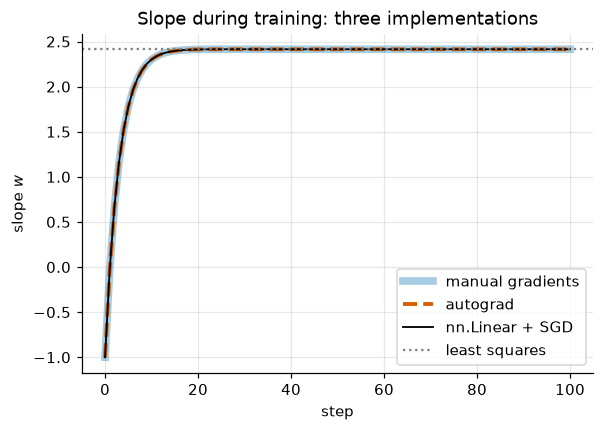

In [24]:
fig, ax = plt.subplots(figsize=(6, 4))
steps_axis = torch.arange(STEPS + 1)
ax.plot(steps_axis, manual_path[:, 0], lw=5, alpha=0.35, label="manual gradients")
ax.plot(steps_axis, autograd_path[:, 0], lw=2.5, ls="--", label="autograd")
ax.plot(steps_axis, module_path[:, 0], lw=1.2, color="k", label="nn.Linear + SGD")
ax.axhline(w_ls, color="gray", ls=":", label="least squares")
ax.set_xlabel("step")
ax.set_ylabel("slope $w$")
ax.set_title("Slope during training: three implementations")
ax.legend()
plt.show()

The three curves lie exactly on top of each other: they are three ways of writing one algorithm. From here on we use the `nn.Module` style, knowing what it does underneath.

### Checkpoint 5.1

Do exactly **one** optimizer step. Create `model_c = nn.Linear(1, 1)`, set its weight and bias to 0 (inside `torch.no_grad()`), make an `SGD` optimizer with `lr=0.1`, and take one standard training step on `X1`, `Y1` with `nn.MSELoss()`. After the step, its weight and bias should equal the `w_1` and `b_1` of Checkpoint 3.1, because it is the same step from the same start.

<details>
<summary><b>💡 Hint</b></summary>

`model_c.weight.fill_(0.0)` inside `with torch.no_grad():`. Then `optimizer.zero_grad()`, forward, loss, `backward()`, `step()` — once, no loop.

</details>

In [25]:
model_c = nn.Linear(1, 1)
with torch.no_grad():
    model_c.weight.fill_(0.0)
    model_c.bias.fill_(0.0)
opt_c = torch.optim.SGD(model_c.parameters(), lr=0.1)
opt_c.zero_grad()
nn.MSELoss()(model_c(X1), Y1).backward()
opt_c.step()

In [26]:
check_shape(model_c.weight, (1, 1), "model_c.weight")
_gw, _gb = mse_grads(0.0, 0.0, x, y)
check_close(model_c.weight.item(), (-0.1 * _gw).item(), "model_c.weight after one step")
check_close(model_c.bias.item(), (-0.1 * _gb).item(), "model_c.bias after one step")
passed("Checkpoint 5.1")

✅ Checkpoint 5.1 passed


## 6. Many features

Real inputs have many numbers per example: a house has a size, an age, a number of rooms. With $D$ features, example $i$ is a row vector $\mathbf{x}_i \in \mathbb{R}^D$, the data form a matrix $X \in \mathbb{R}^{N \times D}$ (one example per row), and the model is

$$\hat{y}_i = \mathbf{x}_i \cdot \mathbf{w} + b, \qquad \hat{\mathbf{y}} = X\mathbf{w} + b\mathbf{1},$$

with weight vector $\mathbf{w} \in \mathbb{R}^D$, a scalar $b$, and $\hat{\mathbf{y}}$ of shape `(N,)`. We generate data with $D = 3$, $\mathbf{w}^* = (1.5, -2, 0.5)$, $b^* = 0.3$, and the same noise level.

In [27]:
D = 3
W_STAR = torch.tensor([1.5, -2.0, 0.5])   # (D,)
B_STAR = 0.3

gen = torch.Generator().manual_seed(1)
X = torch.randn(N, D, generator=gen)                                  # (N, D)
y6 = X @ W_STAR + B_STAR + SIGMA * torch.randn(N, generator=gen)      # (N,)
print("X:", tuple(X.shape), "  y6:", tuple(y6.shape))

A6 = torch.cat([X.double(), torch.ones(N, 1, dtype=torch.float64)], dim=1)       # (N, D + 1)
theta6_ls = torch.linalg.lstsq(A6, y6.double().unsqueeze(1)).solution.squeeze(1)  # (D + 1,)
w6_ls, b6_ls = theta6_ls[:D], theta6_ls[D]
print("least squares w:", [round(v, 4) for v in w6_ls.tolist()], " b:", round(b6_ls.item(), 4))

X: (100, 3)   y6: (100,)
least squares w: [1.4703, -2.0094, 0.4555]  b: 0.2816


### The vectorized gradient

With residuals $\mathbf{r} = \hat{\mathbf{y}} - \mathbf{y}$ (shape `(N,)`), the derivation of Section 3 applies to each weight: $\partial L/\partial w_j = \frac2N \sum_i r_i X_{ij}$. The sum over $i$ of $X_{ij} r_i$ is entry $j$ of $X^\top \mathbf{r}$, so all $D$ partial derivatives at once are

$$\nabla_{\mathbf{w}} L = \frac{2}{N} X^\top(\hat{\mathbf{y}} - \mathbf{y}) \quad (\text{shape } (D,)), \qquad \frac{\partial L}{\partial b} = \frac{2}{N}\sum_i (\hat y_i - y_i).$$

Shapes: $X^\top$ is `(D, N)`, $\mathbf{r}$ is `(N,)`, product `(D,)` — one number per weight, as a gradient must be. For $D = 1$ this is exactly Section 3's formula. We check it against autograd:

In [28]:
w_test = torch.tensor([0.1, 0.2, 0.3], requires_grad=True)
b_test = torch.tensor(-0.5, requires_grad=True)
mse(X @ w_test + b_test, y6).backward()

with torch.no_grad():
    r = X @ w_test + b_test - y6             # (N,)
    grad_w_vec = 2 / N * X.T @ r             # (D,)
    grad_b_vec = 2 * r.mean()
print("vectorized formula:", grad_w_vec.tolist(), grad_b_vec.item())
print("autograd:          ", w_test.grad.tolist(), b_test.grad.item())
check_close(grad_w_vec, w_test.grad, "vectorized dL/dw")
check_close(grad_b_vec, b_test.grad, "vectorized dL/db")
passed("Vectorized gradient matches autograd")

vectorized formula: [-2.661375045776367, 3.739109992980957, -0.23604360222816467] -1.0751945972442627
autograd:           [-2.661375045776367, 3.739109754562378, -0.23604363203048706] -1.0751945972442627
✅ Vectorized gradient matches autograd passed


**Why least squares has a closed form.** Fold $b$ into the weights with the design matrix $A = [X, \mathbf{1}]$ of shape `(N, D+1)`, as in Section 2. The gradient is $\frac2N A^\top(A\boldsymbol\theta - \mathbf y)$, and at the minimum it is zero: $A^\top A\,\boldsymbol\theta = A^\top \mathbf y$. These are the **normal equations**, a linear system `lstsq` solves (by a numerically safer route than inverting $A^\top A$). This works only because the gradient is linear in $\boldsymbol\theta$; for neural networks it is not, and iterative descent is the only option.

Now train with `nn.Linear(3, 1)`: weight `(1, 3)`, bias `(1,)`, input `(N, 3)`, output `(N, 1)`.

In [29]:
torch.manual_seed(0)
model6 = nn.Linear(D, 1)
optimizer6 = torch.optim.SGD(model6.parameters(), lr=0.1)
Y6 = y6.unsqueeze(1)   # (N, 1)
for step in range(300):
    optimizer6.zero_grad()
    loss = loss_fn(model6(X), Y6)
    loss.backward()
    optimizer6.step()

print("nn.Linear w:", [round(v, 4) for v in model6.weight.squeeze(0).tolist()], " b:", round(model6.bias.item(), 4))
print("lstsq     w:", [round(v, 4) for v in w6_ls.tolist()], " b:", round(b6_ls.item(), 4))
check_close(model6.weight.squeeze(0), w6_ls, "model6 weight", rtol=0, atol=1e-5)
check_close(model6.bias.squeeze(0), b6_ls, "model6 bias", rtol=0, atol=1e-5)
passed("nn.Linear(3, 1) reaches the least-squares solution")

nn.Linear w: [1.4703, -2.0094, 0.4555]  b: 0.2816
lstsq     w: [1.4703, -2.0094, 0.4555]  b: 0.2816
✅ nn.Linear(3, 1) reaches the least-squares solution passed


The model started from PyTorch's random initialization (seeded) and still reached the same answer: a convex quadratic bowl has one minimum, and gradient descent with a stable $\eta$ finds it from anywhere.

### Checkpoint 6.1

Shapes are where linear-model bugs hide. Compute `pred6` = the predictions of `model6` on `X` as a tensor of shape `(N,)` (not `(N, 1)`), and `pred6_manual` = the same predictions computed as $X\mathbf{w} + b$ from `model6.weight` and `model6.bias` without calling the model. Both inside `torch.no_grad()`.

<details>
<summary><b>💡 Hint</b></summary>

`model6(X)` is `(N, 1)`; `.squeeze(1)` removes the size-1 axis. `model6.weight` is `(1, D)`, so use `model6.weight.squeeze(0)` (shape `(D,)`) or `X @ model6.weight.T` (shape `(N, 1)`).

</details>

In [30]:
with torch.no_grad():
    pred6 = model6(X).squeeze(1)
    pred6_manual = X @ model6.weight.squeeze(0) + model6.bias

In [31]:
check_shape(pred6, (N,), "pred6")
check_shape(pred6_manual, (N,), "pred6_manual")
with torch.no_grad():
    check_close(pred6, (X @ model6.weight.T + model6.bias).squeeze(1), "pred6")
check_close(pred6_manual, pred6, "pred6_manual")
passed("Checkpoint 6.1")

✅ Checkpoint 6.1 passed


## 7. Feature scaling and conditioning

Suppose feature 0 had been recorded in different units with an offset — say $x^{\text{raw}}_{i0} = 100\,x_{i0} + 500$ — while the others are unchanged. This is common: a price in cents next to a rating from 1 to 5. The **information** is identical: a linear model can undo any scaling and shift, and least squares finds the same predictions. But gradient descent behaves very differently.

In [32]:
X_raw = X.clone()
X_raw[:, 0] = 100 * X[:, 0] + 500                      # (N, D)
A_raw = torch.cat([X_raw.double(), torch.ones(N, 1, dtype=torch.float64)], dim=1)   # (N, D + 1)
theta_raw_ls = torch.linalg.lstsq(A_raw, y6.double().unsqueeze(1)).solution.squeeze(1)
print("lstsq on raw features: w =", [round(v, 5) for v in theta_raw_ls[:D].tolist()], " b =", round(theta_raw_ls[D].item(), 4))
pred_gap = (A_raw @ theta_raw_ls - A6 @ theta6_ls).abs().max().item()
print(f"largest difference between the two least-squares predictions: {pred_gap:.1e}")

lstsq on raw features: w = [0.0147, -2.00944, 0.45546]  b = -7.07
largest difference between the two least-squares predictions: 4.6e-07


Same predictions (up to `float64` rounding); the parameters just absorb the units: $w_0$ is 100 times smaller than before ($1.4703/100 \approx 0.0147$), and $b$ changes to compensate for the offset of 500.

### The Hessian and its condition number

Differentiate the gradient $\frac2N A^\top(A\boldsymbol\theta - \mathbf y)$ once more: the **Hessian** of the MSE is the constant matrix

$$H = \frac{2}{N} A^\top A \quad \text{(shape } (D+1, D+1)).$$

Because the gradient is affine in $\boldsymbol\theta$, it satisfies $\nabla L(\boldsymbol\theta_1) - \nabla L(\boldsymbol\theta_0) = H(\boldsymbol\theta_1 - \boldsymbol\theta_0)$ exactly; we use that as a numerical check. Notebook 03 showed two facts about gradient descent on such a bowl: it is stable only if $\eta < 2/\lambda_{\max}(H)$, and the number of steps it needs grows with the **condition number** $\kappa = \lambda_{\max}/\lambda_{\min}$.

In [33]:
def hessian_mse(A):
    """Hessian of the MSE for design matrix A: (N, P) -> (P, P)."""
    return 2 / A.shape[0] * A.T @ A


def grad_mse(A, theta, y):
    """Gradient of the MSE for design matrix A (N, P), parameters theta (P,), targets y (N,)."""
    return 2 / A.shape[0] * A.T @ (A @ theta - y)


y6_64 = y6.double()
for name, A_ in [("standard-scale X", A6), ("raw X (feature 0 ×100 + 500)", A_raw)]:
    H = hessian_mse(A_)
    t0, t1 = torch.zeros(D + 1, dtype=torch.float64), torch.randn(D + 1, dtype=torch.float64)
    check_close(grad_mse(A_, t1, y6_64) - grad_mse(A_, t0, y6_64), H @ (t1 - t0), "Hessian check", rtol=1e-9)
    eig = torch.linalg.eigvalsh(H)   # ascending
    print(f"{name:30s} λmin = {eig[0].item():9.3g}   λmax = {eig[-1].item():9.3g}   κ = {(eig[-1] / eig[0]).item():9.3g}   2/λmax = {2 / eig[-1].item():.3g}")

standard-scale X               λmin =      1.68   λmax =      2.74   κ =      1.63   2/λmax = 0.729
raw X (feature 0 ×100 + 500)   λmin =    0.0864   λmax =  5.14e+05   κ =  5.95e+06   2/λmax = 3.89e-06


With all features on a similar scale, $\kappa$ is close to 1 — a round bowl. After rescaling one feature, $\lambda_{\max}$ explodes (the loss is extremely sensitive to $w_0$, because $w_0$ multiplies numbers near 500), so the largest stable $\eta$ becomes tiny. With that tiny $\eta$, the directions with small curvature barely move each step. Let's run gradient descent on both with $\eta = 0.9 \times 2/\lambda_{\max}$, close to the largest stable value for each.

In [34]:
def run_gd(A, y, eta, steps):
    """Gradient descent on the MSE from theta = 0 (float64). Returns (theta history (steps+1, P), loss history)."""
    theta = torch.zeros(A.shape[1], dtype=torch.float64)
    thetas, losses = [theta], [((A @ theta - y) ** 2).mean().item()]
    for _ in range(steps):
        theta = theta - eta * grad_mse(A, theta, y)
        thetas.append(theta)
        losses.append(((A @ theta - y) ** 2).mean().item())
    return torch.stack(thetas), losses


GD_STEPS = 500
eta_raw = 0.9 * 2 / torch.linalg.eigvalsh(hessian_mse(A_raw))[-1].item()
eta_std = 0.9 * 2 / torch.linalg.eigvalsh(hessian_mse(A6))[-1].item()
thetas_raw, losses_raw = run_gd(A_raw, y6_64, eta_raw, GD_STEPS)
thetas_std, losses_std = run_gd(A6, y6_64, eta_std, GD_STEPS)
best = ((A6 @ theta6_ls - y6_64) ** 2).mean().item()
print(f"minimum loss (least squares): {best:.5f}")
for t in [10, 50, 500]:
    print(f"step {t:3d}: raw-feature loss {losses_raw[t]:.5f}   standard-scale loss {losses_std[t]:.5f}")

minimum loss (least squares): 0.22287
step  10: raw-feature loss 5.92090   standard-scale loss 0.22427
step  50: raw-feature loss 5.91746   standard-scale loss 0.22287
step 500: raw-feature loss 5.89717   standard-scale loss 0.22287


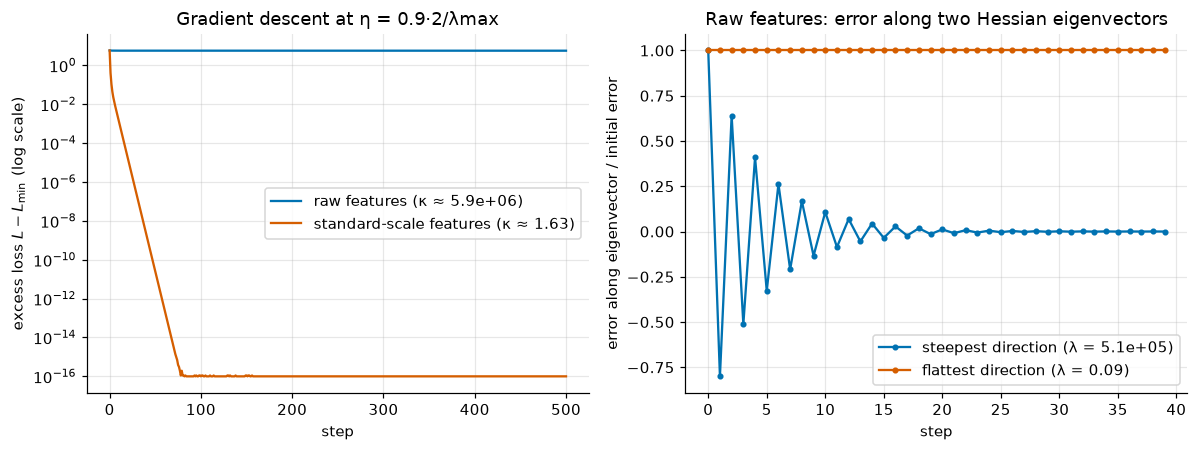

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
kappa = lambda A_: (lambda e: (e[-1] / e[0]).item())(torch.linalg.eigvalsh(hessian_mse(A_)))
ax1.semilogy([l - best for l in losses_raw], label=f"raw features (κ ≈ {kappa(A_raw):.1e})")
ax1.semilogy([max(l - best, 1e-16) for l in losses_std], label=f"standard-scale features (κ ≈ {kappa(A6):.2f})")
ax1.set_xlabel("step")
ax1.set_ylabel("excess loss $L - L_{\\min}$ (log scale)")
ax1.set_title("Gradient descent at η = 0.9·2/λmax")
ax1.legend()

eig_raw, vecs_raw = torch.linalg.eigh(hessian_mse(A_raw))   # columns of vecs_raw are eigenvectors
coords = (thetas_raw - theta_raw_ls) @ vecs_raw                 # (GD_STEPS + 1, D + 1): error along each eigenvector
ax2.plot(coords[:40, -1] / coords[0, -1], ".-", label=f"steepest direction (λ = {eig_raw[-1].item():.1e})")
ax2.plot(coords[:40, 0] / coords[0, 0], ".-", label=f"flattest direction (λ = {eig_raw[0].item():.2f})")
ax2.set_xlabel("step")
ax2.set_ylabel("error along eigenvector / initial error")
ax2.set_title("Raw features: error along two Hessian eigenvectors")
ax2.legend()
plt.tight_layout()
plt.show()

Left: with standard-scale features, the excess loss drops to the rounding floor of `float64` in about 80 steps. With the raw feature, after 500 steps the loss has barely moved from its starting value.

Right: we write the error $\boldsymbol\theta_t - \boldsymbol\theta_{\text{LS}}$ in the eigenvector basis of $H$. Along the steepest direction, each step multiplies the error by $1 - \eta\lambda_{\max} = 1 - 0.9 \cdot 2 = -0.8$: it flips sign every step and shrinks — the zig-zag of notebook 03. Along the flattest direction the factor is $1 - \eta\lambda_{\min} \approx 1 - 1.8/\kappa$, indistinguishable from 1: that error does not visibly shrink at all. Gradient descent is not wrong here; it is just hopelessly slow, because one global $\eta$ must suit both the steepest and the flattest direction.

### Standardization

The fix is to rescale the inputs, not the algorithm. **Standardize** each feature column $j$ to mean 0 and standard deviation 1:

$$z_{ij} = \frac{x_{ij} - \mu_j}{s_j}, \qquad \mu_j = \frac1N\sum_i x_{ij}, \quad s_j = \text{std of column } j.$$

With broadcasting, `mu = X.mean(dim=0)` and `s = X.std(dim=0)` have shape `(D,)` and apply to every row. In real projects, $\mu$ and $s$ are computed on the training data only and reused unchanged for new data (more in notebook 22).

In [36]:
mu_raw = X_raw.mean(dim=0)          # (D,)
s_raw = X_raw.std(dim=0)            # (D,)
Z = (X_raw - mu_raw) / s_raw        # (N, D)
print("column means of Z:", [f"{v:.1e}" for v in Z.mean(dim=0).tolist()])
print("column stds of Z: ", [round(v, 4) for v in Z.std(dim=0).tolist()])

A_z = torch.cat([Z.double(), torch.ones(N, 1, dtype=torch.float64)], dim=1)
eig_z = torch.linalg.eigvalsh(hessian_mse(A_z))
print(f"standardized: κ = {(eig_z[-1] / eig_z[0]).item():.3g}")

torch.manual_seed(0)
model_z = nn.Linear(D, 1)
optimizer_z = torch.optim.SGD(model_z.parameters(), lr=0.1)
for step in range(300):
    optimizer_z.zero_grad()
    loss = loss_fn(model_z(Z), Y6)
    loss.backward()
    optimizer_z.step()
w_std = model_z.weight.detach().squeeze(0)   # (D,) weights for standardized inputs
b_std = model_z.bias.detach().squeeze(0)     # () bias for standardized inputs
print(f"loss after 300 steps on standardized features: {loss.item():.5f}  (minimum {best:.5f})")

column means of Z: ['-8.1e-08', '-3.6e-09', '2.1e-08']
column stds of Z:  [1.0, 1.0, 1.0]
standardized: κ = 1.35
loss after 300 steps on standardized features: 0.22287  (minimum 0.22287)


After standardizing, $\kappa$ is back near 1 and the usual 300 steps at $\eta = 0.1$ reach the minimum. The model learned parameters for $z$, not for the raw features. Since $z_j = (x_j - \mu_j)/s_j$,

$$\hat y = \sum_j w'_j \frac{x_j - \mu_j}{s_j} + b' = \sum_j \underbrace{\frac{w'_j}{s_j}}_{w_j} x_j + \underbrace{\Big(b' - \sum_j \frac{w'_j \mu_j}{s_j}\Big)}_{b},$$

so the raw-scale parameters are $w_j = w'_j / s_j$ and $b = b' - \sum_j w'_j \mu_j / s_j$.

### Checkpoint 7.1

Map `w_std` (shape `(D,)`) and `b_std` (0-d) back to the raw feature scale using `mu_raw` and `s_raw`. Store the results in `w_orig` (shape `(D,)`) and `b_orig` (0-d). The check compares them with least squares on `X_raw`.

<details>
<summary><b>💡 Hint</b></summary>

Elementwise: `w_std / s_raw`. For the bias, `b_std - (w_std * mu_raw / s_raw).sum()`.

</details>

In [37]:
w_orig = w_std / s_raw
b_orig = b_std - (w_std * mu_raw / s_raw).sum()

In [38]:
check_shape(w_orig, (D,), "w_orig")
check_close(w_orig, theta_raw_ls[:D].float(), "w_orig", rtol=1e-4, atol=1e-5)
check_close(b_orig, theta_raw_ls[D].float(), "b_orig", rtol=1e-4, atol=1e-4)
passed("Checkpoint 7.1")

✅ Checkpoint 7.1 passed


## 8. [GPU] A larger regression on the GPU

The training loop is device-agnostic: move the model and the data to `device`, and every operation runs there. Below, a regression with $N = 1{,}000{,}000$ examples and $D = 32$ features (128 MB of `float32` inputs) is trained for 50 steps on the CPU and on the GPU from the same initial parameters, and the results are compared. `float32` throughout, since MPS has no `float64`.

The timings are **indicative only**. GPUs run asynchronously, the first call includes one-time setup, and fair benchmarking needs warm-up runs and explicit synchronization — Chapter 5 teaches how. Here, reading the parameters back with `.cpu()` at the end forces all GPU work to finish before the clock stops.

In [39]:
def train_big(X, Y, device, steps=50, lr=0.2):
    """Full-batch SGD on nn.Linear from zero initialization. X: (N, D), Y: (N, 1)."""
    model = nn.Linear(X.shape[1], 1)
    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()
    model = model.to(device)
    X, Y = X.to(device), Y.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    start = time.perf_counter()
    for _ in range(steps):
        optimizer.zero_grad()
        loss = nn.functional.mse_loss(model(X), Y)
        loss.backward()
        optimizer.step()
    w, b = model.weight.detach().cpu(), model.bias.detach().cpu()  # waits for the device to finish
    return w, b, time.perf_counter() - start


if device.type == "cpu":
    print("No GPU selected; skipping. (Set up Colab with a GPU runtime to try this.)")
else:
    gen = torch.Generator().manual_seed(2)
    N_big, D_big = 1_000_000, 32
    X_big = torch.randn(N_big, D_big, generator=gen)                    # (N_big, D_big)
    w_big = torch.randn(D_big, generator=gen)                           # (D_big,)
    Y_big = (X_big @ w_big + 0.1 + SIGMA * torch.randn(N_big, generator=gen)).unsqueeze(1)  # (N_big, 1)

    w_cpu, b_cpu, t_cpu = train_big(X_big, Y_big, torch.device("cpu"))
    w_dev, b_dev, t_dev = train_big(X_big, Y_big, device)
    print(f"CPU: {t_cpu:.2f} s   {device.type.upper()}: {t_dev:.2f} s   (indicative only, see above)")
    print(f"largest |CPU − {device.type.upper()}| weight difference: {(w_cpu - w_dev).abs().max().item():.1e}")
    print(f"largest |weight − true weight| on CPU: {(w_cpu.squeeze(0) - w_big).abs().max().item():.1e}")
    check_close(w_dev, w_cpu, "device weights", rtol=1e-4, atol=1e-4)
    check_close(b_dev, b_cpu, "device bias", rtol=1e-4, atol=1e-4)
    passed("GPU training matches CPU training")

CPU: 0.20 s   MPS: 0.23 s   (indicative only, see above)
largest |CPU − MPS| weight difference: 6.0e-08
largest |weight − true weight| on CPU: 1.1e-03
✅ GPU training matches CPU training passed


CPU and GPU agree to within `float32` rounding (the two devices sum the million terms of each gradient in different orders), and with a million examples the fitted weights are within about $10^{-3}$ of the true ones: more data, less noise in the estimate.

## Exercises

### Exercise 1 (modify): how large can the learning rate be?

The cell below trains the 1-feature model of Section 5 with several learning rates and plots the loss curves. It also computes $\lambda_{\max}$ of the Hessian $H = \frac2N A^\top A$ for this data (Section 7).

1. Run it. For each $\eta$ in the list, say whether training converges smoothly, converges while oscillating, or diverges.
2. Edit `etas` to include values just below and just above $2/\lambda_{\max}$ (for example $0.98$ and $1.02$ times it) and run again.
3. Relate what you see to $1/\lambda_{\max}$ and $2/\lambda_{\max}$. Answer in the markdown cell below.

<details>
<summary><b>💡 Hint</b></summary>

Along the Hessian's top eigenvector, one gradient step multiplies the distance to the minimum by $1 - \eta\lambda_{\max}$ (notebook 03). Ask when that factor is positive, when it is negative but larger than $-1$, and when it is below $-1$.

</details>

λmax = 2.7636   1/λmax = 0.3619   2/λmax = 0.7237
η =  0.100  ( 0.28 / λmax)   loss after 60 steps: 0.1978
η =  0.300  ( 0.83 / λmax)   loss after 60 steps: 0.1978
η =  0.500  ( 1.38 / λmax)   loss after 60 steps: 0.1978
η =  0.700  ( 1.93 / λmax)   loss after 60 steps: 0.2043
η =  0.750  ( 2.07 / λmax)   loss after 60 steps: 7.65e+04
η =  0.900  ( 2.49 / λmax)   loss after 60 steps: 4.25e+21


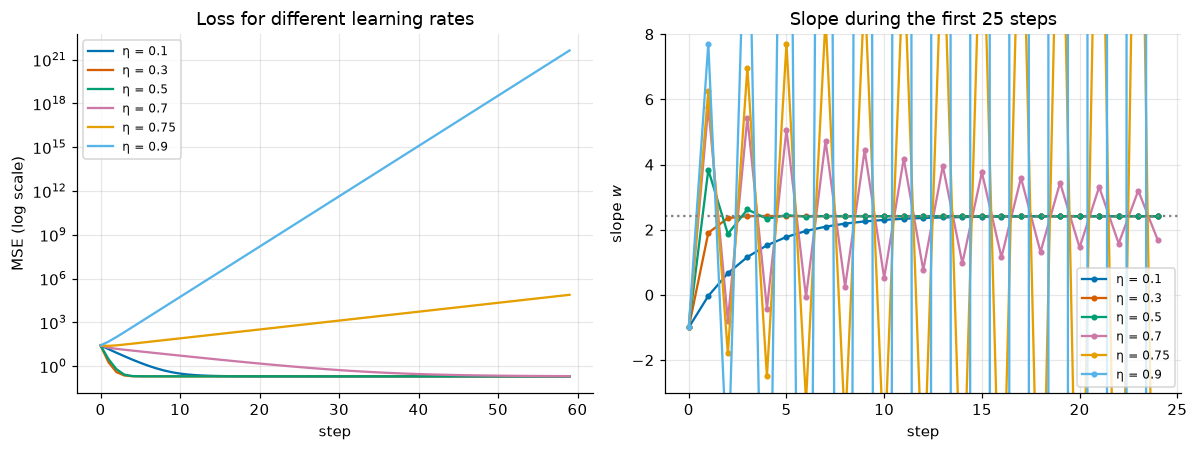

In [40]:
H1 = hessian_mse(A)                       # (2, 2) Hessian of the 1-feature problem
lam_max = torch.linalg.eigvalsh(H1)[-1].item()
print(f"λmax = {lam_max:.4f}   1/λmax = {1 / lam_max:.4f}   2/λmax = {2 / lam_max:.4f}")

etas = [0.1, 0.3, 0.5, 0.7, 0.75, 0.9]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for k, eta_k in enumerate(etas):
    m = nn.Linear(1, 1)
    with torch.no_grad():
        m.weight.fill_(W0)
        m.bias.fill_(B0)
    opt = torch.optim.SGD(m.parameters(), lr=eta_k)
    losses, slopes = [], []
    for step in range(60):
        opt.zero_grad()
        loss = loss_fn(m(X1), Y1)
        losses.append(loss.item())
        slopes.append(m.weight.item())
        loss.backward()
        opt.step()
    ax1.semilogy(losses, color=COLORS[k % len(COLORS)], label=f"η = {eta_k:.3g}")
    ax2.plot(slopes[:25], ".-", color=COLORS[k % len(COLORS)], label=f"η = {eta_k:.3g}")
    print(f"η = {eta_k:6.3f}  ({eta_k * lam_max:5.2f} / λmax)   loss after 60 steps: {losses[-1]:.4g}")
ax1.set_xlabel("step")
ax1.set_ylabel("MSE (log scale)")
ax1.set_title("Loss for different learning rates")
ax1.legend(fontsize=8)
ax2.axhline(w_ls, color="gray", ls=":")
ax2.set_ylim(-3, 8)
ax2.set_xlabel("step")
ax2.set_ylabel("slope $w$")
ax2.set_title("Slope during the first 25 steps")
ax2.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

*Your answer:*

> **Worked solution.**
>
> For this data $\lambda_{\max} \approx 2.76$, so $1/\lambda_{\max} \approx 0.36$ and $2/\lambda_{\max} \approx 0.72$.
>
> - $\eta = 0.1$ and $0.3$ (below $1/\lambda_{\max}$): smooth, monotone convergence; the slope approaches $w_{\text{LS}}$ from one side. $0.3$ is faster.
> - $\eta = 0.5$ and $0.7$ (between $1/\lambda_{\max}$ and $2/\lambda_{\max}$): still converge, but the slope overshoots and alternates sides of the minimum. At $0.7$ the factor $1 - 0.7 \cdot 2.76 \approx -0.93$ is close to $-1$, so the oscillation decays slowly and the loss after 60 steps is visibly above the minimum.
> - $\eta = 0.75$ and $0.9$ (above $2/\lambda_{\max}$): the factor is below $-1$, every step overshoots by more than it corrects, and the loss grows exponentially.
>
> With $0.98$ and $1.02$ times $2/\lambda_{\max}$, the first barely converges (factor $\approx -0.96$) and the second slowly diverges (factor $\approx -1.04$): the threshold $2/\lambda_{\max}$ is sharp, exactly as the analysis of a quadratic predicts. The other eigenvalue, $\lambda_{\min} \approx 1.99$, is never the problem: its stability limit $2/\lambda_{\min}$ is larger. The largest stable step is set by the *steepest* direction.

### Exercise 2 (implement): linear regression with manual vectorized gradients

Write `fit_linear_regression(X, y, lr, steps)` for $X$ of shape `(N, D)` and $y$ of shape `(N,)`. Start from $\mathbf w = \mathbf 0$ (shape `(D,)`) and $b = 0$, run `steps` gradient-descent steps on the MSE using the formulas of Section 6 — **no autograd, no `nn.Module`** — and return `(w, b)` with `w` of shape `(D,)` and `b` a 0-d tensor.

<details>
<summary><b>💡 Hint</b></summary>

Inside the loop: `r = X @ w + b - y` (shape `(N,)`), then `w = w - lr * 2 / N * X.T @ r` and `b = b - lr * 2 * r.mean()`. Use the dtype of `X` for the zeros: `torch.zeros(D, dtype=X.dtype)`.

</details>

In [41]:
def fit_linear_regression(X, y, lr, steps):
    n, d = X.shape
    w = torch.zeros(d, dtype=X.dtype)
    b = torch.zeros((), dtype=X.dtype)
    for _ in range(steps):
        r = X @ w + b - y              # (N,)
        w = w - lr * 2 / n * X.T @ r   # (D,)
        b = b - lr * 2 * r.mean()
    return w, b

In [42]:
w_fit, b_fit = fit_linear_regression(X, y6, lr=0.1, steps=300)
check_shape(w_fit, (D,), "w")
check_shape(b_fit, (), "b")
check(not w_fit.requires_grad, "do not use autograd: w should not require gradients")
check_close(w_fit, w6_ls.float(), "w", rtol=0, atol=1e-5)
check_close(b_fit, b6_ls.float(), "b", rtol=0, atol=1e-5)
w1_fit, b1_fit = fit_linear_regression(X1, y, lr=0.1, steps=300)
check_close(w1_fit, torch.tensor([w_ls], dtype=torch.float32), "w for the 1-feature data", rtol=0, atol=1e-5)
check_close(b1_fit, torch.tensor(b_ls, dtype=torch.float32), "b for the 1-feature data", rtol=0, atol=1e-5)
passed("Exercise 2")

✅ Exercise 2 passed


### Exercise 3 (debug): a loop that trains to the wrong answer

This function is supposed to fit a line with `nn.Linear` to `x` of shape `(N,)` and `y` of shape `(N,)`. The buggy version (in the comments) runs without any error and its loss decreases — but the final parameters are wrong. It contains **two** bugs. Find both and write the corrected loop body.

<details>
<summary><b>💡 Hint</b></summary>

Print the shape of `model(X_in) - y` in the buggy version. Then remember what `backward()` does to `.grad` if nothing clears it. (`nn.MSELoss` would have printed a warning about the first bug; a hand-written loss prints nothing.)

</details>

In [43]:
def train_line(x, y, lr=0.1, steps=300):
    torch.manual_seed(0)
    model = nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    X_in = x.unsqueeze(1)                      # (N, 1)
    for _ in range(steps):
        # Buggy version:
        #     y_hat = model(X_in)
        #     loss = ((y_hat - y) ** 2).mean()
        #     loss.backward()
        #     optimizer.step()
        optimizer.zero_grad()
        y_hat = model(X_in).squeeze(1)         # (N,), same shape as y
        loss = ((y_hat - y) ** 2).mean()
        loss.backward()
        optimizer.step()
    return model

In [44]:
fitted = train_line(x, y)
check_close(fitted.weight.item(), w_ls, "fitted slope", rtol=0, atol=1e-4)
check_close(fitted.bias.item(), b_ls, "fitted intercept", rtol=0, atol=1e-4)
passed("Exercise 3")

✅ Exercise 3 passed


To see what the bugs do, here is the buggy loop run directly:

In [45]:
def train_line_buggy(x, y, lr=0.1, steps=300, zero_grad=False, fix_shape=False):
    torch.manual_seed(0)
    model = nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    X_in = x.unsqueeze(1)
    for _ in range(steps):
        if zero_grad:
            optimizer.zero_grad()
        y_hat = model(X_in)                    # (N, 1)
        if fix_shape:
            y_hat = y_hat.squeeze(1)           # (N,)
        loss = ((y_hat - y) ** 2).mean()       # unfixed: (N, 1) - (N,) broadcasts to (N, N)!
        loss.backward()
        optimizer.step()
    return model


print("shape of y_hat - y in the buggy loop:", tuple((model(X1) - y).shape))
for zg, fs, label in [(False, False, "both bugs"), (True, False, "shape bug only"), (False, True, "zero_grad bug only")]:
    m = train_line_buggy(x, y, zero_grad=zg, fix_shape=fs)
    print(f"{label:20s}: w = {m.weight.item():8.4f}, b = {m.bias.item():8.4f}")
print(f"{'least squares':20s}: w = {w_ls:8.4f}, b = {b_ls:8.4f}   (mean of y = {y.mean().item():.4f})")

shape of y_hat - y in the buggy loop: (100, 100)
both bugs           : w =  -0.0043, b =  -2.8093
shape bug only      : w =   0.0000, b =  -1.1172
zero_grad bug only  : w =   4.7441, b =  -2.5662
least squares       : w =   2.4143, b =  -1.0054   (mean of y = -1.1172)


> **Worked solution.**
>
> **Bug 1 (shape).** `model(X_in)` has shape `(N, 1)` and `y` has shape `(N,)`. Broadcasting turns `y_hat - y` into an `(N, N)` matrix with entries $\hat y_i - y_j$: every prediction is compared with *every* target. The mean of its squares is minimized when each $\hat y_i$ equals the mean of all targets, so the model learns $w \approx 0$ and $b \approx \bar y$ — a flat line — with a perfectly smooth, decreasing loss. The output above shows exactly that when the gradients are zeroed. Fix: make the shapes equal, e.g. `model(X_in).squeeze(1)` (or compare with `y.unsqueeze(1)`).
>
> **Bug 2 (no `zero_grad`).** Without `optimizer.zero_grad()`, each `backward()` adds the new gradient to all previous ones, so step $t$ uses the *sum* of every gradient so far. That is no longer gradient descent: the accumulated gradient keeps pushing in old directions after the parameters have passed the minimum, like a ball rolling in a bowl with no friction. (Writing out two consecutive updates on a quadratic gives $\boldsymbol\theta_{t+1} - 2\boldsymbol\theta_t + \boldsymbol\theta_{t-1} = -\eta H(\boldsymbol\theta_t - \boldsymbol\theta^*)$, an undamped oscillation.) The parameters swing around the minimum forever, so where they end depends on when the loop stops: with only this bug, $w \approx 4.74$ after 300 steps. Fix: call `optimizer.zero_grad()` at the start of each step.
>
> Fixing only one of the two bugs is not enough, as the table above shows.
>
> Lesson: a decreasing loss does not prove a correct loop. Check shapes, and compare with a known answer when you have one.

### Exercise 4 (investigate): outliers — MSE versus mean absolute error

Section 1 derived MSE from Gaussian noise. Notebook 04 showed that **Laplace** noise, with density $\propto e^{-|y - \hat y|/s}$, gives negative log-likelihood $\frac1s\sum_i |y_i - \hat y_i| + \text{const}$, so maximum likelihood minimizes the **mean absolute error** (MAE) $\frac1N\sum_i|\hat y_i - y_i|$.

The scaffold adds 5 gross outliers to our data, fits a line with each loss using autograd and full-batch gradient descent, and plots the fitted lines and the per-example gradient magnitude $|\partial \ell_i / \partial \hat y_i|$ against the residual. Run it, then answer in the markdown cell:

1. Which fitted line is pulled by the outliers, and by how much (compare with least squares on the clean data)?
2. Using the right plot, explain *why*: how much can a single example push the parameters under each loss?
3. What is the cost of MAE? (Look at the loss curves and think about $|r|$ at $r = 0$.)

Optionally change `n_out` or `out_shift` and see how the two fits respond.

<details>
<summary><b>💡 Hint</b></summary>

For one example, $\frac{d}{d\hat y}(\hat y - y)^2 = 2(\hat y - y)$ grows without bound with the residual, while $\frac{d}{d\hat y}|\hat y - y| = \operatorname{sign}(\hat y - y)$ has size 1 for every residual. Gradient descent sums these pushes over all examples.

</details>

clean least squares: w = 2.414, b = -1.005
MSE with outliers:   w = 1.879, b = -1.560
MAE with outliers:   w = 2.390, b = -1.014


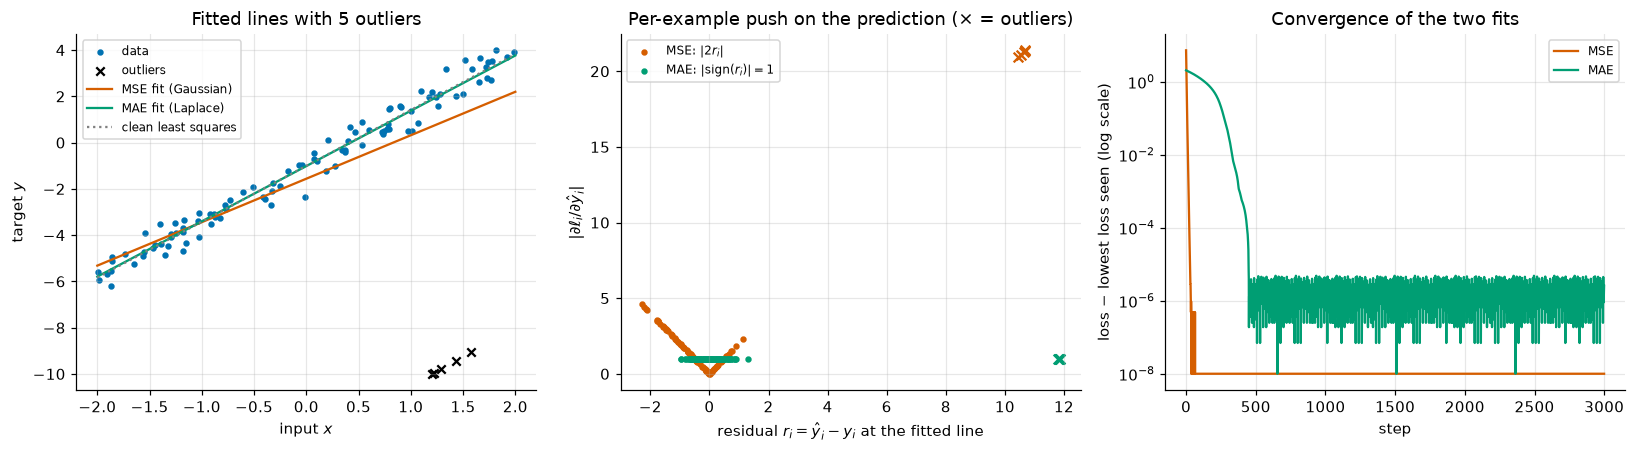

In [46]:
n_out, out_shift = 5, -12.0
gen = torch.Generator().manual_seed(3)
x_out = 1.2 + 0.8 * torch.rand(n_out, generator=gen)            # outliers at the right edge
y_out = TRUE_W * x_out + TRUE_B + out_shift                     # far below the line
x_all = torch.cat([x, x_out])                                   # (N + n_out,)
y_all = torch.cat([y, y_out])


def fit_with(loss_name, lr, steps=3000):
    """Fit w*x + b to (x_all, y_all) from (0, 0) with autograd. Returns w, b, loss history."""
    w = torch.zeros((), requires_grad=True)
    b = torch.zeros((), requires_grad=True)
    history = []
    for _ in range(steps):
        r = w * x_all + b - y_all
        loss = (r**2).mean() if loss_name == "MSE" else r.abs().mean()
        history.append(loss.item())
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()
    return w.item(), b.item(), history


w_mse, b_mse, hist_mse = fit_with("MSE", lr=0.1)
w_mae, b_mae, hist_mae = fit_with("MAE", lr=0.01)
print(f"clean least squares: w = {w_ls:.3f}, b = {b_ls:.3f}")
print(f"MSE with outliers:   w = {w_mse:.3f}, b = {b_mse:.3f}")
print(f"MAE with outliers:   w = {w_mae:.3f}, b = {b_mae:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
grid_x = torch.linspace(-2, 2, 2)
axes[0].scatter(x, y, s=10, color=COLORS[0], label="data")
axes[0].scatter(x_out, y_out, s=30, color="k", marker="x", label="outliers")
axes[0].plot(grid_x, w_mse * grid_x + b_mse, color=COLORS[1], label="MSE fit (Gaussian)")
axes[0].plot(grid_x, w_mae * grid_x + b_mae, color=COLORS[2], label="MAE fit (Laplace)")
axes[0].plot(grid_x, w_ls * grid_x + b_ls, color="gray", ls=":", label="clean least squares")
axes[0].set_xlabel("input $x$")
axes[0].set_ylabel("target $y$")
axes[0].set_title("Fitted lines with 5 outliers")
axes[0].legend(fontsize=8)

r_mse = w_mse * x_all + b_mse - y_all
r_mae = w_mae * x_all + b_mae - y_all
is_out = torch.arange(len(x_all)) >= N
for r_, g_, c_, lab in [(r_mse, 2 * r_mse.abs(), COLORS[1], "MSE: $|2r_i|$"), (r_mae, torch.ones_like(r_mae), COLORS[2], "MAE: $|\\mathrm{sign}(r_i)| = 1$")]:
    axes[1].scatter(r_[~is_out], g_[~is_out], s=10, color=c_, label=lab)
    axes[1].scatter(r_[is_out], g_[is_out], s=40, color=c_, marker="x")
axes[1].set_xlabel("residual $r_i = \\hat y_i - y_i$ at the fitted line")
axes[1].set_ylabel("$|\\partial \\ell_i / \\partial \\hat y_i|$")
axes[1].set_title("Per-example push on the prediction (× = outliers)")
axes[1].legend(fontsize=8)

axes[2].semilogy(torch.tensor(hist_mse) - min(hist_mse) + 1e-8, color=COLORS[1], label="MSE")
axes[2].semilogy(torch.tensor(hist_mae) - min(hist_mae) + 1e-8, color=COLORS[2], label="MAE")
axes[2].set_xlabel("step")
axes[2].set_ylabel("loss − lowest loss seen (log scale)")
axes[2].set_title("Convergence of the two fits")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

*Your conclusion:*

> **Worked solution.**
>
> **What happens.** Without outliers, least squares gives $w \approx 2.414$, $b \approx -1.005$. With 5 outliers among 105 points (under 5% of the data), the MSE fit drops to $w \approx 1.88$, $b \approx -1.56$: the whole line tilts toward the outliers and misfits the 100 good points. The MAE fit gives $w \approx 2.39$, $b \approx -1.01$, almost the clean answer.
>
> **Why.** The gradient of either loss is an average of per-example pushes, $\frac1N\sum_i \frac{\partial \ell_i}{\partial \hat y_i}\,(x_i, 1)$, and the fit stops where the pushes balance. Under MSE the push is $2r_i$, proportional to the residual: at the MSE fit each outlier pushes with strength about 21, while the good points push with at most about 5. Five outliers are as loud as dozens of good points, so the line must move far toward them before the good points push back hard enough. Under MAE every example pushes with strength exactly 1 whatever its residual, so 5 outliers carry only the weight of 5 ordinary points; the fit is like a median and barely moves. In likelihood terms: the Gaussian density decays like $e^{-r^2/2\sigma^2}$, so a residual of 10 is astronomically unlikely and the fit bends to avoid it; the Laplace density decays only like $e^{-|r|/s}$, so it "expects" occasional large errors.
>
> **The cost.** $|r|$ has a kink at $r = 0$, and its gradient does not shrink as the fit improves. With a fixed $\eta$, the MAE fit needed about 450 steps (MSE: a few dozen) and then never settled: its loss keeps jittering about $10^{-6}$ above the best value as points cross from one side of the line to the other. In practice this calls for a decaying learning rate, or a compromise such as the Huber loss (quadratic for small residuals, linear for large ones). And if the noise really is Gaussian, MSE is the maximum-likelihood choice and uses the data more efficiently (stated without proof).

## Summary and what's next

- A learning problem has a **model** with parameters, a **loss**, and an **optimizer**. For a line, $\hat y = wx + b$; the MSE loss is the Gaussian negative log-likelihood up to constants, so minimizing it is maximum likelihood.
- The MSE gradient is $\frac2N X^\top(\hat{\mathbf y} - \mathbf y)$ for the weights and $\frac2N\sum_i(\hat y_i - y_i)$ for the bias. We derived it, checked it with finite differences and autograd, and used it in gradient descent.
- Manual gradients, autograd, and `nn.Linear` + `torch.optim.SGD` produce the *same* path step by step. The standard training step is `zero_grad → forward → loss → backward → step`.
- Linear least squares has an exact answer (the normal equations); we used it as ground truth. Neural networks will have none.
- The speed of gradient descent depends on the conditioning of the loss: badly scaled features give a huge $\kappa$ and a tiny stable $\eta$. Standardizing features fixes this, and the parameters can be mapped back to the original units.
- Silent bugs — broadcasting `(N, 1)` against `(N,)`, forgetting `zero_grad` — train to wrong answers without any error. Compare with a known answer when you can.

That completes Chapter 1: tensors, linear algebra, gradients, probability, autograd, and now a full training loop. But a linear model can only draw straight lines and flat planes. Chapter 2 turns to **classification**, starting with the perceptron in notebook 07, and soon meets tasks that no single linear model can solve — which is what motivates stacking layers into neural networks.